In [ ]:
from google.colab import files
import io
import pandas as pd

uploaded = files.upload()

# Use the first uploaded CSV file
csv_filename = next(
    (filename for filename in uploaded if filename.lower().endswith(".csv")),
    None
)

if csv_filename is None:
    raise ValueError("Please upload the Kaggle SMS Spam Collection CSV file.")

# latin-1 handles the encoding used by the common Kaggle copy
df = pd.read_csv(io.BytesIO(uploaded[csv_filename]), encoding="latin-1")

# The common Kaggle file names its label and message columns v1 and v2.
# This fallback handles CSV copies where those columns have different names.
if {"v1", "v2"}.issubset(df.columns):
    df = df[["v1", "v2"]].copy()
    df.columns = ["label", "text"]
else:
    df = df.iloc[:, :2].copy()
    df.columns = ["label", "text"]

# Clean up rows and standardize labels
df = df.dropna(subset=["label", "text"]).copy()
df["label"] = df["label"].astype(str).str.strip().str.lower()
df["text"] = df["text"].astype(str)

# Encode ham as 0 and spam as 1
df["label"] = df["label"].map({"ham": 0, "spam": 1})
df = df.dropna(subset=["label"]).copy()
df["label"] = df["label"].astype(int)

print("Dataset loaded:", csv_filename)
print("Number of messages:", len(df))
print("\nClass counts:")
print(df["label"].map({0: "ham", 1: "spam"}).value_counts())
print("\nFirst five messages:")
display(df.head())

Saving spam.csv to spam.csv
Dataset loaded: spam.csv
Number of messages: 5572

Class counts:
label
ham     4825
spam     747
Name: count, dtype: int64

First five messages:


,label,text
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [ ]:
from sklearn.model_selection import train_test_split

X = df["text"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Training messages: {len(X_train)}")
print(f"Test messages:     {len(X_test)}")
print(f"Spam in training:  {y_train.mean():.1%}")
print(f"Spam in test:      {y_test.mean():.1%}")

Training messages: 4457
Test messages:     1115
Spam in training:  13.4%
Spam in test:      13.4%


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

models = {
    "Naive Bayes": Pipeline([
        ("tfidf", TfidfVectorizer(stop_words="english")),
        ("classifier", MultinomialNB())
    ]),
    "Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer(stop_words="english")),
        ("classifier", LogisticRegression(max_iter=1000, random_state=42))
    ])
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"Trained: {name}")

Trained: Naive Bayes
Trained: Logistic Regression


Naive Bayes
Accuracy: 0.9686

Classification report:
                  precision    recall  f1-score   support

ham (legitimate)       0.97      1.00      0.98       966
            spam       1.00      0.77      0.87       149

        accuracy                           0.97      1115
       macro avg       0.98      0.88      0.92      1115
    weighted avg       0.97      0.97      0.97      1115



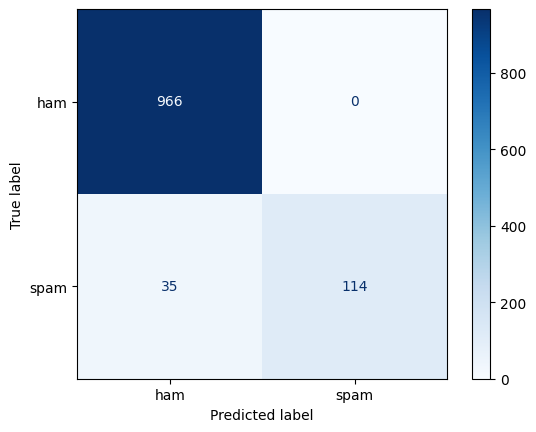

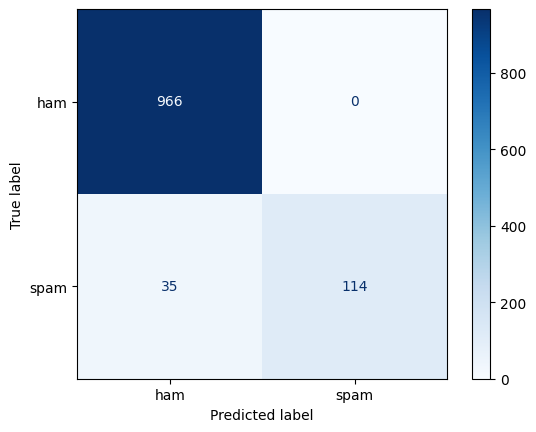

Logistic Regression
Accuracy: 0.9677

Classification report:
                  precision    recall  f1-score   support

ham (legitimate)       0.96      1.00      0.98       966
            spam       1.00      0.76      0.86       149

        accuracy                           0.97      1115
       macro avg       0.98      0.88      0.92      1115
    weighted avg       0.97      0.97      0.97      1115



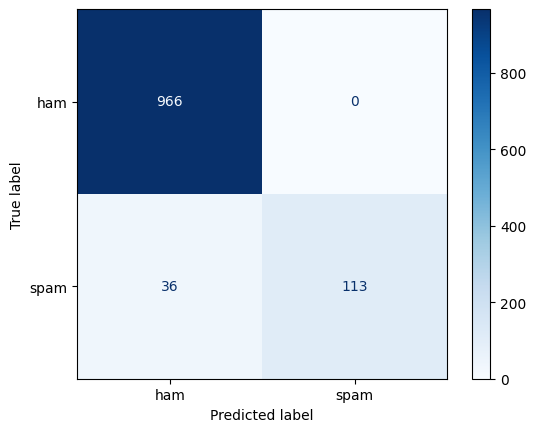

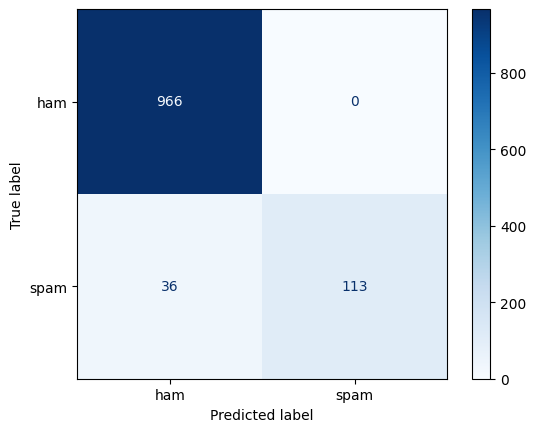

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

for name, model in models.items():
    predictions = model.predict(X_test)

    print("=" * 60)
    print(name)
    print(f"Accuracy: {accuracy_score(y_test, predictions):.4f}")
    print("\nClassification report:")
    print(classification_report(
        y_test,
        predictions,
        labels=[0, 1],
        target_names=["ham (legitimate)", "spam"],
        zero_division=0
    ))

    cm = confusion_matrix(y_test, predictions, labels=[0, 1])
    display(
        ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=["ham", "spam"]
        ).plot(cmap="Blues", values_format="d").figure_
    )
    plt.show()

In [ ]:
# Choose the model with the higher test accuracy
best_model_name = max(
    models,
    key=lambda name: accuracy_score(y_test, models[name].predict(X_test))
)
best_model = models[best_model_name]

print("Selected model:", best_model_name)

new_messages = [
    "Congratulations! You have won a free iPhone. Call now to claim your prize.",
    "Hi, are we still meeting for lunch today?",
    "URGENT! You have won a prize. Text WIN to 80085 now."
]

predictions = best_model.predict(new_messages)
probabilities = best_model.predict_proba(new_messages)[:, 1]

for message, prediction, spam_probability in zip(
    new_messages, predictions, probabilities
):
    label = "SPAM" if prediction == 1 else "HAM (legitimate)"
    print(f"\nMessage: {message}")
    print(f"Prediction: {label}")
    print(f"Estimated spam probability: {spam_probability:.1%}")

Selected model: Naive Bayes

Message: Congratulations! You have won a free iPhone. Call now to claim your prize.
Prediction: SPAM
Estimated spam probability: 88.5%

Message: Hi, are we still meeting for lunch today?
Prediction: HAM (legitimate)
Estimated spam probability: 0.3%

Message: URGENT! You have won a prize. Text WIN to 80085 now.
Prediction: SPAM
Estimated spam probability: 91.9%


In [ ]:
message = input("Enter an SMS message: ")

prediction = best_model.predict([message])[0]
spam_probability = best_model.predict_proba([message])[0, 1]

if prediction == 1:
    print("Prediction: SPAM")
else:
    print("Prediction: HAM (legitimate)")

print(f"Estimated spam probability: {spam_probability:.1%}")

Enter an SMS message: welcome to xyz limited, please click the link to claim your discount [some link]
Prediction: SPAM
Estimated spam probability: 58.3%


In [ ]:
import joblib
from google.colab import files

# Save the trained model
joblib.dump(best_model, "spam_model.pkl")

# Download it to your computer
files.download("spam_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>